<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_heterogeneity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Spatial heterogeneity: GWR and MGWR of poverty on night-time lights

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

Night-time lights are a common proxy for economic activity. Is their link with poverty the same everywhere in Bolivia? This notebook regresses **multidimensional poverty** (`sdg1_2_mpi`, 2012, 0–1; **higher = poorer**) from the Atlas de los ODS en Bolivia 2026 on **log night-time lights per capita** (`ln_t400NTLpc`, 2012) and lets the relationship vary over space. It then repeats the exercise for the latest period: poverty around the 2024 census on lights in 2020, the last year of the lights series.

Outline:

1. **Load** the data with `geo4bolivia`
2. **Global regression** (OLS): one slope for the whole country
3. **Geographically weighted regression** (GWR): one slope per municipality, a single bandwidth
4. **Multiscale GWR** (MGWR): a separate bandwidth for the intercept and the slope
5. **Comparison** of the three models
6. **A second period**: poverty in 2024 on lights in 2020

## 0. Setup

In Google Colab the next cell installs what Colab lacks (a few seconds). Locally, `uv sync` has installed everything already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify", "mgwr"]
           if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q {" ".join(missing)}

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

import geo4bolivia as geo
from mgwr.gwr import GWR, MGWR
from mgwr.sel_bw import Sel_BW
from mgwr.diagnostics import get_AICc
from spglm.glm import GLM

import warnings
warnings.filterwarnings("ignore")

## 1. Load the data

Poverty comes from the SDG Atlas, which gives every one of the 343 municipalities and indigenous autonomies two values: one near the 2012 census and one near the 2024 census (stored as years 2012 and 2024). Night-time lights per capita (`ntl`, 2012–2020) are built from gridded population on the older municipal map, so they cover **333 units**: the four units created since (three indigenous autonomies, TIOC, and San Pedro de Macha) and the six municipalities that ceded territory to them have no lights value. The regressions use these 333 units.

`ln_t400NTLpc` is the Hodrick–Prescott trend of the log of lights per capita, which removes year-to-year noise. The GWR kernels need one point per municipality: we use the centroids in the observatory's equal-area projection, in kilometres.

In [3]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi", years=[2012, 2024], wide="sdg1_2_mpi")
ntl = geo.load("ntl", variables="ln_t400NTLpc", years=[2012, 2020], wide="ln_t400NTLpc")

units = geo.units("municipality")
departments = geo.units("department").set_index("geo_id")["name"]

gdf = (geo.boundaries("municipality")
          .merge(mpi, on="geo_id")
          .merge(ntl, on="geo_id")               # inner join: the 333 units with lights
          .merge(units[["geo_id", "department_id"]], on="geo_id"))
gdf["department"] = gdf["department_id"].map(departments)
gdf = gdf.to_crs(geo.config()["equal_area_crs"])

no_lights = units.loc[~units["geo_id"].isin(ntl["geo_id"]), ["geo_id", "name"]]
print("Units without lights:", ", ".join(no_lights["name"]))

MPI, NTL = "sdg1_2_mpi2012", "ln_t400NTLpc2012"
print(gdf.shape, "| missing values:", int(gdf[[MPI, NTL]].isna().sum().sum()))
gdf[["geo_id", "name", "department", MPI, NTL]].head()

Units without lights: Mizque, TIOC-Raqaypampa, San Ignacio, Santa Ana, TIOC-Territorio Indígena Multiétnico, Porco, Tomave, TIOC-Jatun Ayllu Yura, Colquechaca, San Pedro de Macha
(333, 9) | missing values: 0


,geo_id,name,department,sdg1_2_mpi2012,ln_t400NTLpc2012
0,BO-01-01-01,Azurduy,Chuquisaca,0.512,11.048312
1,BO-01-01-02,Tarvita,Chuquisaca,0.452,12.329279
2,BO-01-02-01,Villa Serrano,Chuquisaca,0.267,12.815315
3,BO-01-03-01,Huacareta,Chuquisaca,0.346,12.018971
4,BO-01-03-02,Monteagudo,Chuquisaca,0.212,14.603350


In [4]:
y = gdf[[MPI]].values                       # (333, 1)
X = gdf[[NTL]].values                       # (333, 1); mgwr adds the intercept
centroids = gdf.geometry.centroid
coords = np.column_stack([centroids.x, centroids.y]) / 1000   # km

# department outlines for the maps
dep_lines = geo.boundaries("department").to_crs(gdf.crs).boundary
print(f"y {y.shape}, X {X.shape}, coords {coords.shape}")

y (333, 1), X (333, 1), coords (333, 2)


## 2. Global regression

Ordinary least squares fits one intercept and one slope for the whole country.

In [5]:
ols = sm.OLS(y, sm.add_constant(X)).fit()
print(ols.summary(xname=["const", NTL], yname=MPI).tables[1])
print(f"R2 = {ols.rsquared:.3f} | sd of MPI = {gdf[MPI].std():.3f}")

                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.6658      0.037     17.805      0.000       0.592       0.739
ln_t400NTLpc2012    -0.0333      0.003    -11.716      0.000      -0.039      -0.028
R2 = 0.293 | sd of MPI = 0.104


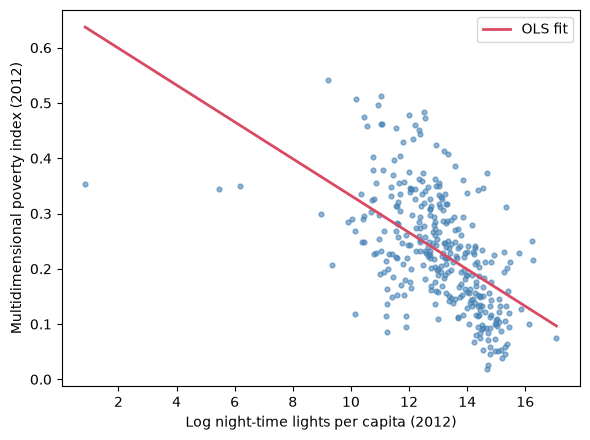

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(gdf[NTL], gdf[MPI], s=12, alpha=0.6, color="steelblue")
xs = np.linspace(gdf[NTL].min(), gdf[NTL].max(), 100)
ax.plot(xs, ols.params[0] + ols.params[1] * xs, color="#d84a64", lw=2, label="OLS fit")
ax.set_xlabel("Log night-time lights per capita (2012)")
ax.set_ylabel("Multidimensional poverty index (2012)")
ax.legend()
plt.tight_layout()
plt.show()

Across the country, brighter municipalities are less poor. The OLS slope is −0.033: one more log point of lights per capita (about 2.7 times more light per person) goes with an MPI 0.033 lower, about a third of the cross-municipal standard deviation of poverty (0.104). Lights alone explain 29% of the variation in poverty (R² = 0.293). One very dark outlier sits on the far left (Mojinete, Potosí, with a log of 0.86 against 5.47 for the next darkest municipality), and the cloud of points is wide, which suggests that one slope may not fit all regions.

## 3. Geographically weighted regression (GWR)

GWR estimates a separate regression at each municipality, weighting the other municipalities by distance with an adaptive bisquare kernel. The **bandwidth** (the number of nearest neighbours in each local regression) is chosen by minimising AICc: a small bandwidth means the relationship changes quickly over space.

In [7]:
gwr_selector = Sel_BW(coords, y, X)
gwr_bw = gwr_selector.search(criterion="AICc")
print("GWR bandwidth (nearest neighbours) =", gwr_bw)

GWR bandwidth (nearest neighbours) = 46.0


In [8]:
gwr_results = GWR(coords, y, X, gwr_bw, name_x=[NTL]).fit()
gwr_results.summary()

Model type                                                         Gaussian
Number of observations:                                                 333
Number of covariates:                                                     2

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                              2.520
Log-likelihood:                                                     340.649
AIC:                                                               -677.297
AICc:                                                              -675.224
BIC:                                                              -1919.975
R2:                                                                   0.293
Adj. R2:                                                              0.291

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [9]:
print("Bandwidth confidence interval:", gwr_results.get_bws_intervals(gwr_selector))
print(f"R2 = {gwr_results.R2:.3f}, adj. R2 = {gwr_results.adj_R2:.3f}, AICc = {gwr_results.aicc:.1f}, "
      f"OLS AICc = {get_AICc(GLM(y, sm.add_constant(X), constant=False).fit()):.1f}")

Bandwidth confidence interval: (np.float64(46.0), np.float64(50.0))
R2 = 0.633, adj. R2 = 0.587, AICc = -813.6, OLS AICc = -675.2


In [10]:
gdf["gwr_intercept"] = gwr_results.params[:, 0]
gdf["gwr_slope"] = gwr_results.params[:, 1]
gdf["gwr_R2"] = gwr_results.localR2[:, 0]

gwr_sig = gwr_results.filter_tvals(alpha=0.05)    # 0 where |t| < 1.96
gwr_sig_c = gwr_results.filter_tvals()            # 0 where not significant after correction for multiple tests
print("Significant slopes (5%):", int((gwr_sig[:, 1] != 0).sum()),
      "| after correction:", int((gwr_sig_c[:, 1] != 0).sum()), "of", len(gdf),
      f"| adjusted critical t = {gwr_results.critical_tval():.2f}")
print("Negative slopes:", int((gdf["gwr_slope"] < 0).sum()))
gdf[["gwr_intercept", "gwr_slope", "gwr_R2"]].describe().round(4)

Significant slopes (5%): 284 | after correction: 182 of 333 | adjusted critical t = 3.02
Negative slopes: 333


,gwr_intercept,gwr_slope,gwr_R2
count,333.0000,333.0000,333.0000
mean,0.7871,-0.0422,0.4950
std,0.3503,0.0252,0.2062
min,0.2994,-0.0947,0.0868
25%,0.5030,-0.0672,0.3448
50%,0.6270,-0.0323,0.4925
75%,1.1396,-0.0224,0.6973
max,1.4810,-0.0061,0.8227


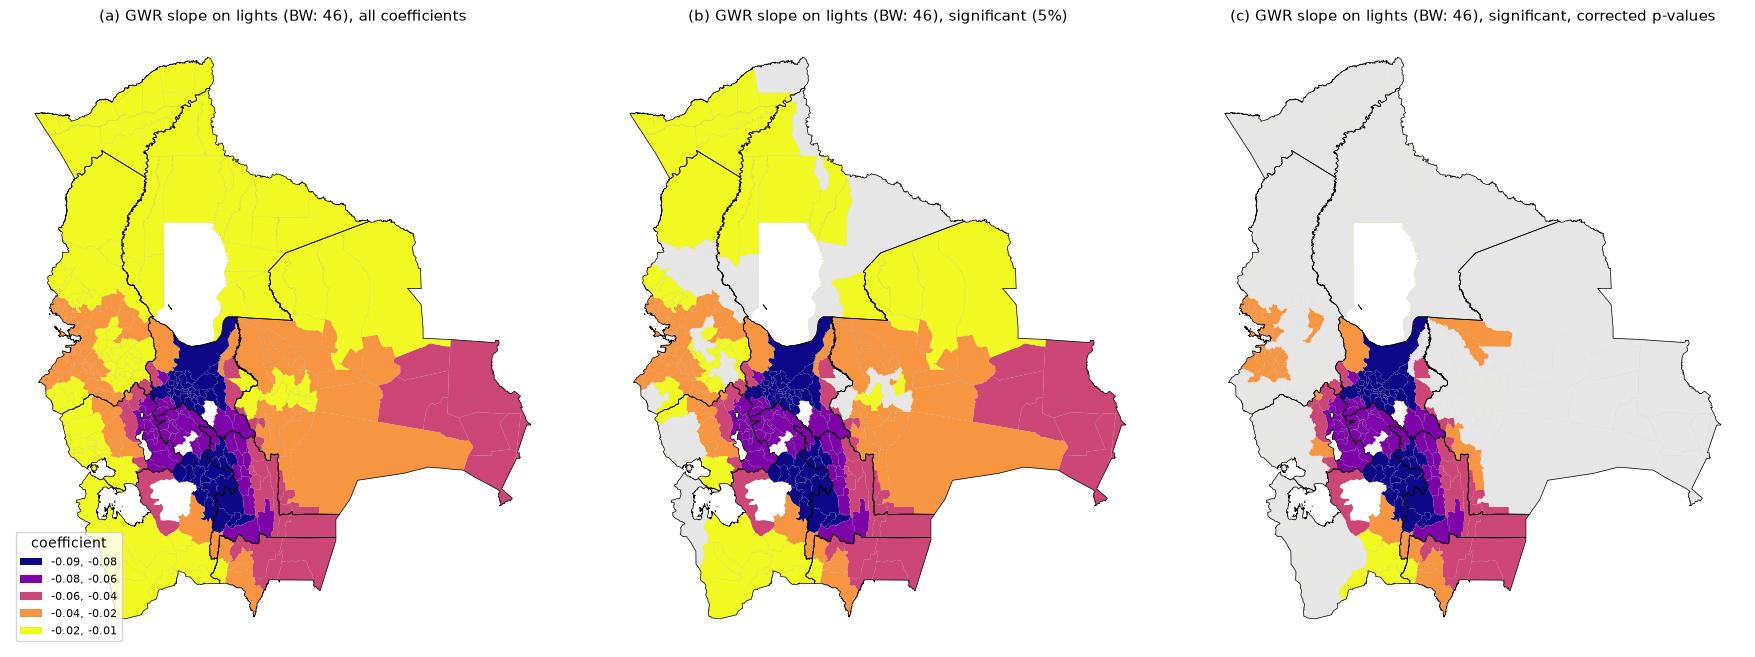

In [11]:
def plot_coefficient(column, sig, sig_c, title, bw):
    """Three maps: all local coefficients, significant ones (5%), significant after correction.
    Non-significant municipalities are shaded light grey."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.5))
    kw = dict(column=column, cmap="plasma", scheme="FisherJenks", k=5, linewidth=0.05, edgecolor="grey")
    panels = [("all coefficients", None),
              ("significant (5%)", sig),
              ("significant, corrected p-values", sig_c)]
    for i, (ax, (label, mask)) in enumerate(zip(axes, panels)):
        gdf.plot(ax=ax, legend=(i == 0),
                 legend_kwds={"loc": "lower left", "fontsize": 8, "title": "coefficient"}, **kw)
        if mask is not None:
            gdf[mask == 0].plot(ax=ax, color="#e6e6e6", edgecolor="#e6e6e6", linewidth=0.3)
        dep_lines.plot(ax=ax, color="black", linewidth=0.5)
        ax.set_title(f"({'abc'[i]}) {title} (BW: {bw}), {label}", fontsize=11)
        ax.set_axis_off()
    plt.tight_layout()
    plt.show()

plot_coefficient("gwr_slope", gwr_sig[:, 1], gwr_sig_c[:, 1], "GWR slope on lights", int(gwr_bw))

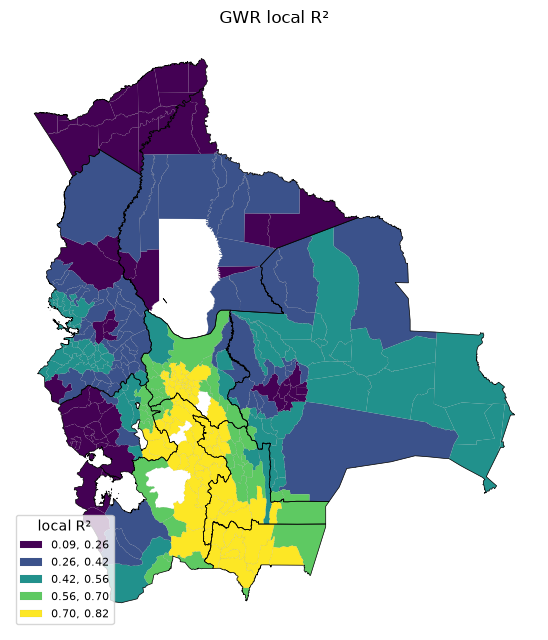

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
gdf.plot(column="gwr_R2", cmap="viridis", scheme="FisherJenks", k=5, linewidth=0.05, edgecolor="grey",
         legend=True, legend_kwds={"loc": "lower left", "fontsize": 8, "title": "local R²"}, ax=ax)
dep_lines.plot(ax=ax, color="black", linewidth=0.5)
ax.set_title("GWR local R²")
ax.set_axis_off()
plt.tight_layout()
plt.show()

The AICc-optimal bandwidth is **46 nearest neighbours** (95% interval 46–50), about 14% of the 333 municipalities, so each local regression is genuinely local. Letting the relationship vary raises R² from 0.293 to 0.633 (adjusted 0.587) and lowers AICc from −675.2 to −813.6, with about 37 effective parameters.

- **The sign never changes**: all 333 local slopes are negative, from −0.095 to −0.006 (mean −0.042). More light goes with less poverty everywhere; what varies is the strength.
- The slope is **steepest in the Andean valleys** of Cochabamba, Chuquisaca and Potosí (department averages −0.077, −0.067 and −0.057; Vitichi, Camargo and Caiza "D" reach about −0.09), and also steep in the Chaco and along the eastern border of Santa Cruz (Cuevo, Boyuibe, Camiri, Puerto Suárez, about −0.05).
- It is **weakest in the Amazonian north**: Beni and Pando average −0.014, with San Borja, San Buenaventura and Rurrenabaque the flattest (−0.006 to −0.009). La Paz averages −0.026.
- 284 local slopes are significant at 5%, and 182 after correcting for the multiple tests that GWR implies (adjusted critical t = 3.02). Most of the 49 slopes not significant even at 5% lie in La Paz (13), Oruro (12), Beni (10) and Santa Cruz (8).
- The local R² follows the same geography: above 0.65 in 101 municipalities, all of them in Cochabamba, Potosí, Chuquisaca, Tarija (all 11) and Oruro (4), with a maximum of 0.82 around Villa Charcas, Camargo and Tinguipaya. It falls below 0.25 in 52 municipalities: the western highlands of Oruro (17), all of Pando (15), and the cities of Santa Cruz de la Sierra and La Paz (0.09 and 0.11).

## 4. Multiscale GWR (MGWR)

GWR forces the intercept and the slope to vary at the same spatial scale. MGWR selects **one bandwidth per coefficient**: a bandwidth close to the number of municipalities (333) means the coefficient is essentially global, a small one means it is local. As in the original DS4Bolivia notebook, the variables are standardised (mean 0, standard deviation 1), so the slope is in standard deviations of MPI per standard deviation of lights.

In [13]:
Zy = (y - y.mean(axis=0)) / y.std(axis=0)
ZX = (X - X.mean(axis=0)) / X.std(axis=0)

mgwr_selector = Sel_BW(coords, Zy, ZX, multi=True)
mgwr_bw = mgwr_selector.search(criterion="AICc")
print("MGWR bandwidths (intercept, lights) =", mgwr_bw)

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

MGWR bandwidths (intercept, lights) = [44. 64.]


In [14]:
mgwr_results = MGWR(coords, Zy, ZX, mgwr_selector, name_x=[NTL]).fit()
mgwr_results.summary()

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

Model type                                                         Gaussian
Number of observations:                                                 333
Number of covariates:                                                     2

Global Regression Results
---------------------------------------------------------------------------
Residual sum of squares:                                            235.385
Log-likelihood:                                                    -414.744
AIC:                                                                833.488
AICc:                                                               835.561
BIC:                                                              -1687.110
R2:                                                                   0.293
Adj. R2:                                                              0.291

Variable                              Est.         SE  t(Est/SE)    p-value
------------------------------- ---------- ---------- ------

In [15]:
print("Bandwidth confidence intervals:", mgwr_results.get_bws_intervals(mgwr_selector))
print(f"R2 = {mgwr_results.R2:.3f}, adj. R2 = {mgwr_results.adj_R2:.3f}, AICc = {mgwr_results.aicc:.1f}")

Bandwidth confidence intervals: [(np.float64(44.0), np.float64(48.0)), (np.float64(64.0), np.float64(84.0))]
R2 = 0.645, adj. R2 = 0.605, AICc = 678.1


In [16]:
gdf["mgwr_intercept"] = mgwr_results.params[:, 0]
gdf["mgwr_slope"] = mgwr_results.params[:, 1]

mgwr_sig = mgwr_results.filter_tvals(alpha=0.05)
mgwr_sig_c = mgwr_results.filter_tvals()
print("Significant slopes (5%):", int((mgwr_sig[:, 1] != 0).sum()),
      "| after correction:", int((mgwr_sig_c[:, 1] != 0).sum()), "of", len(gdf))
print("Negative slopes:", int((gdf["mgwr_slope"] < 0).sum()))
gdf[["mgwr_intercept", "mgwr_slope"]].describe().round(4)

Significant slopes (5%): 324 | after correction: 250 of 333
Negative slopes: 333


,mgwr_intercept,mgwr_slope
count,333.0000,333.0000
mean,0.0398,-0.6675
std,0.3738,0.3813
min,-0.8025,-1.3571
25%,-0.2949,-1.0544
50%,0.0996,-0.4525
75%,0.3899,-0.3942
max,0.6454,-0.1676


In [17]:
# average local estimates by department
(gdf.groupby("department")[["gwr_slope", "gwr_R2", "mgwr_slope"]]
    .mean().sort_values("mgwr_slope").round(3))

,gwr_slope,gwr_R2,mgwr_slope
department,,,
Cochabamba,-0.077,0.686,-1.239
Chuquisaca,-0.067,0.701,-1.022
Potosí,-0.057,0.672,-0.905
Oruro,-0.040,0.341,-0.701
Tarija,-0.041,0.746,-0.572
Santa Cruz,-0.035,0.416,-0.478
La Paz,-0.026,0.415,-0.413
Pando,-0.014,0.220,-0.275
Beni,-0.014,0.307,-0.263


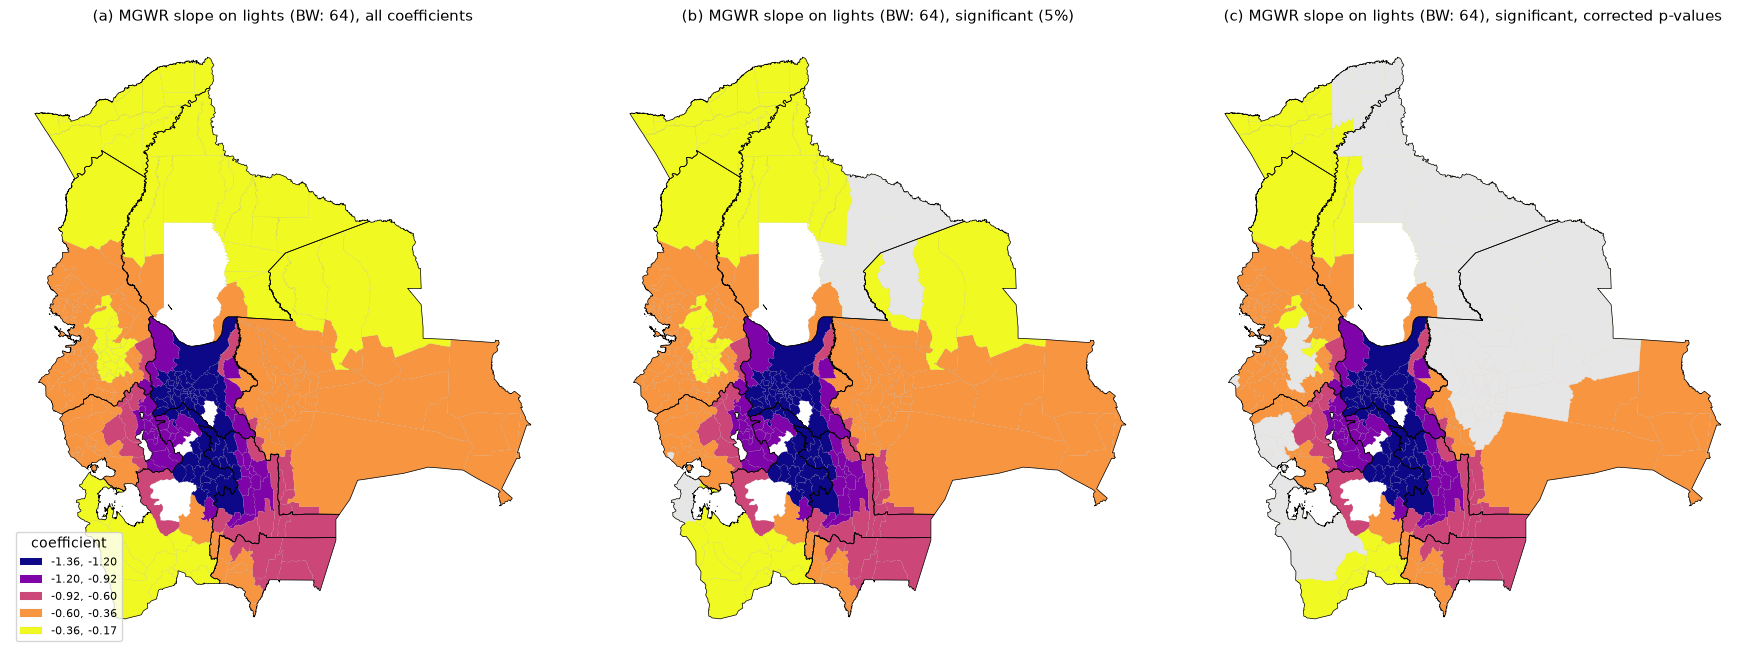

In [18]:
plot_coefficient("mgwr_slope", mgwr_sig[:, 1], mgwr_sig_c[:, 1],
                 "MGWR slope on lights", int(mgwr_bw[1]))

MGWR selects a bandwidth of **44 neighbours for the intercept** (interval 44–48) and **64 for the slope on lights** (interval 64–84). Both are far below 333, so both the baseline level of poverty and its link with lights vary locally; the slope varies over a somewhat larger scale than the intercept, a difference GWR cannot detect because it uses one bandwidth for both.

In standardised units, every local slope is again negative, from −1.36 to −0.17 standard deviations of MPI per standard deviation of lights (OLS: −0.54). 324 slopes are significant at 5% and 250 after correction. The map repeats the GWR pattern, more smoothly: the strongest association in Cochabamba (average −1.24), Chuquisaca (−1.02) and Potosí (−0.91), and the weakest in Beni (−0.26), Pando (−0.28) and La Paz (−0.41).

## 5. Comparison

To compare like with like, the three models are evaluated on the standardised variables (GWR's bandwidth and fit do not change with standardisation; only the scale of AICc does).

In [19]:
def compare(Zy, ZX, gwr_bw, mgwr_bw, mgwr_res, ols_adj_r2):
    ols_z = GLM(Zy, sm.add_constant(ZX), constant=False).fit()
    gwr_z = GWR(coords, Zy, ZX, gwr_bw).fit()
    table = pd.DataFrame({
        "OLS":  {"bandwidth (intercept, lights)": "global", "R2": 1 - ols_z.deviance / ols_z.null_deviance,
                 "adj. R2": ols_adj_r2, "AICc": get_AICc(ols_z), "effective parameters": 2.0},
        "GWR":  {"bandwidth (intercept, lights)": f"{int(gwr_bw)}, {int(gwr_bw)}", "R2": gwr_z.R2,
                 "adj. R2": gwr_z.adj_R2, "AICc": gwr_z.aicc, "effective parameters": gwr_z.ENP},
        "MGWR": {"bandwidth (intercept, lights)": f"{int(mgwr_bw[0])}, {int(mgwr_bw[1])}", "R2": mgwr_res.R2,
                 "adj. R2": mgwr_res.adj_R2, "AICc": mgwr_res.aicc, "effective parameters": mgwr_res.ENP},
    }).T
    return table.astype({c: float for c in table.columns[1:]})

comparison = compare(Zy, ZX, gwr_bw, mgwr_bw, mgwr_results, ols.rsquared_adj)
comparison.round(3)

,"bandwidth (intercept, lights)",R2,adj. R2,AICc,effective parameters
OLS,global,0.293,0.291,835.561,2.000
GWR,"46, 46",0.633,0.587,697.206,36.993
MGWR,"44, 64",0.645,0.605,678.051,33.871


- Both local models fit far better than OLS: R² rises from 0.29 to 0.63 (GWR) and 0.65 (MGWR). **MGWR is preferred**: it has the lowest AICc (678.1, against 697.2 for GWR and 835.6 for OLS) with fewer effective parameters than GWR (33.9 against 37.0).
- **The relationship is spatially heterogeneous but has one sign.** Lights are associated with lower poverty in every municipality. In MGWR the association is almost five times stronger in Cochabamba than in Beni (department averages −1.24 and −0.26), and locally it ranges eightfold (−1.36 to −0.17).

## 6. A second period: poverty in 2024 on lights in 2020

The Atlas measures poverty again around the 2024 census; the lights series ends in 2020. The same three models, on the same 333 units, show whether the link has changed. The variables are standardised as in section 4, so the slopes of the two periods are comparable even though poverty fell a lot.

In [20]:
MPI24, NTL20 = "sdg1_2_mpi2024", "ln_t400NTLpc2020"
print(gdf[[MPI, MPI24, NTL, NTL20]].describe().round(3))

y24, X24 = gdf[[MPI24]].values, gdf[[NTL20]].values
ols24 = sm.OLS(y24, sm.add_constant(X24)).fit()
print(f"OLS 2024: slope = {ols24.params[1]:.4f} (t = {ols24.tvalues[1]:.1f}), R2 = {ols24.rsquared:.3f}")

gwr24_bw = Sel_BW(coords, y24, X24).search(criterion="AICc")
Zy24 = (y24 - y24.mean(axis=0)) / y24.std(axis=0)
ZX24 = (X24 - X24.mean(axis=0)) / X24.std(axis=0)
mgwr24_selector = Sel_BW(coords, Zy24, ZX24, multi=True)
mgwr24_bw = mgwr24_selector.search(criterion="AICc")
mgwr24 = MGWR(coords, Zy24, ZX24, mgwr24_selector).fit()

comparison24 = compare(Zy24, ZX24, gwr24_bw, mgwr24_bw, mgwr24, ols24.rsquared_adj)
pd.concat({"MPI 2012 on lights 2012": comparison, "MPI 2024 on lights 2020": comparison24}).round(3)

       sdg1_2_mpi2012  sdg1_2_mpi2024  ln_t400NTLpc2012  ln_t400NTLpc2020
count         333.000         333.000           333.000           333.000
mean            0.231           0.062            13.030            14.044
std             0.104           0.042             1.682             1.184
min             0.018           0.003             0.856            10.488
25%             0.152           0.030            12.041            13.174
50%             0.226           0.053            13.118            14.101
75%             0.298           0.081            14.277            14.933
max             0.541           0.223            17.071            18.063
OLS 2024: slope = -0.0178 (t = -10.5), R2 = 0.251


Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

bandwidth (intercept, lights)     R2  adj. R2  \
MPI 2012 on lights 2012 OLS                         global  0.293    0.291   
                        GWR                         46, 46  0.633    0.587   
                        MGWR                        44, 64  0.645    0.605   
MPI 2024 on lights 2020 OLS                         global  0.251    0.249   
                        GWR                         46, 46  0.545    0.487   
                        MGWR                       44, 100  0.536    0.492   

                                 AICc  effective parameters  
MPI 2012 on lights 2012 OLS   835.561                 2.000  
                        GWR   697.206                36.993  
                        MGWR  678.051                33.871  
MPI 2024 on lights 2020 OLS   854.759                 2.000  
                        GWR   769.813                37.244  
                        MGWR  755.923                29.303

Bandwidth confidence intervals 2024: [(np.float64(44.0), np.float64(48.0)), (np.float64(100.0), np.float64(111.0))]
Negative MGWR slopes 2024: 333 | significant after correction: 242 of 333
Correlation of the local slopes, 2012 vs 2024: 0.84


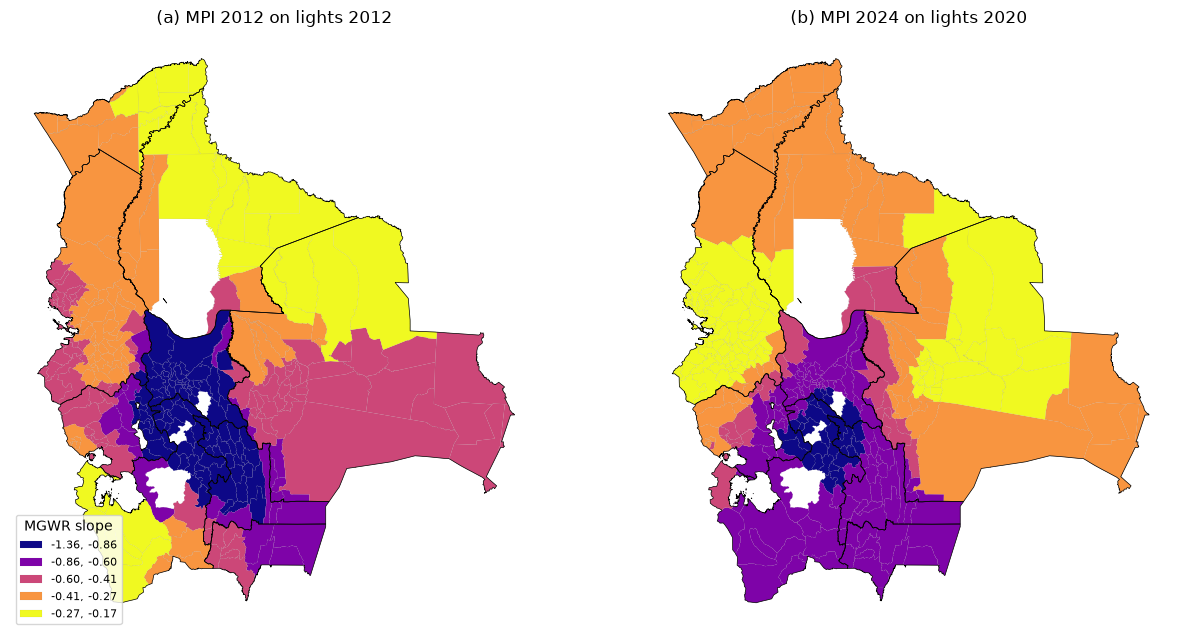

,mgwr_slope,mgwr_slope_2024
department,,
Cochabamba,-1.239,-0.770
Chuquisaca,-1.022,-0.771
Potosí,-0.905,-0.830
Oruro,-0.701,-0.568
Tarija,-0.572,-0.742
Santa Cruz,-0.478,-0.343
La Paz,-0.413,-0.228
Pando,-0.275,-0.296
Beni,-0.263,-0.333


In [21]:
gdf["mgwr_slope_2024"] = mgwr24.params[:, 1]
mgwr24_sig_c = mgwr24.filter_tvals()
print("Bandwidth confidence intervals 2024:", mgwr24.get_bws_intervals(mgwr24_selector))
print("Negative MGWR slopes 2024:", int((gdf["mgwr_slope_2024"] < 0).sum()),
      "| significant after correction:", int((mgwr24_sig_c[:, 1] != 0).sum()), "of", len(gdf))
print(f"Correlation of the local slopes, 2012 vs 2024: {gdf['mgwr_slope'].corr(gdf['mgwr_slope_2024']):.2f}")

# same classes for both maps
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
bins = np.quantile(pd.concat([gdf["mgwr_slope"], gdf["mgwr_slope_2024"]]), [0.2, 0.4, 0.6, 0.8, 1.0])
for ax, col, title in [(axes[0], "mgwr_slope", "(a) MPI 2012 on lights 2012"),
                       (axes[1], "mgwr_slope_2024", "(b) MPI 2024 on lights 2020")]:
    gdf.plot(column=col, cmap="plasma", scheme="UserDefined", classification_kwds={"bins": bins},
             linewidth=0.05, edgecolor="grey", legend=(col == "mgwr_slope"),
             legend_kwds={"loc": "lower left", "fontsize": 8, "title": "MGWR slope"}, ax=ax)
    dep_lines.plot(ax=ax, color="black", linewidth=0.5)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

gdf.groupby("department")[["mgwr_slope", "mgwr_slope_2024"]].mean().sort_values("mgwr_slope").round(3)

Between the two censuses multidimensional poverty fell sharply: on these 333 units the average MPI drops from 0.231 to 0.062 (median 0.226 to 0.053), and the spread narrows (standard deviation 0.104 to 0.042). Lights per capita rose (mean log 13.03 to 14.04) and their spread in logs narrowed (standard deviation 1.68 to 1.18).

- **The link persists but is a little weaker.** In 2024 the OLS slope is −0.018 (t = −10.5) in MPI units, half the 2012 slope, but poverty itself is far lower; in standardised terms the global association falls only from −0.54 to −0.50, and R² from 0.293 to 0.251.
- **It is still local.** GWR again selects 46 neighbours and raises R² to 0.545. MGWR keeps a local intercept (44 neighbours) and has the lowest AICc (755.9, against 769.8 for GWR and 854.8 for OLS), with an adjusted R² of 0.492.
- **The slope varies over a broader scale.** Its MGWR bandwidth rises from 64 to 100 neighbours (interval 100–111). All 333 local slopes are still negative and 242 significant after correction, and their map is much the same as in 2012 (correlation 0.84 between the two sets of slopes).
- **The valleys have converged towards the rest.** The strongest associations weaken in Cochabamba (−1.24 to −0.77) and Chuquisaca (−1.02 to −0.77), and La Paz's falls from −0.41 to −0.23, while Tarija's strengthens (−0.57 to −0.74). Potosí (−0.83) now has the steepest average slope.

Lights in 2020 precede poverty in 2024 by four years, so this is a comparison of patterns, not a test of how the lights predict later poverty.

## Summary

- **One sign, many strengths.** In both periods, every one of the 333 local slopes is negative: brighter municipalities are less poor everywhere, but the strength of the link varies about eightfold in 2012.
- **Local models fit far better.** In 2012, lights explain 29% of poverty globally and about 64% locally (GWR R² = 0.633, MGWR R² = 0.645); MGWR, with an intercept bandwidth of 44 and a slope bandwidth of 64 neighbours, has the lowest AICc.
- **Where lights are informative.** As a proxy for poverty, night-time lights are most informative in the Andean valleys of Cochabamba, Chuquisaca and Potosí and in Tarija, and least informative in the Amazonian north (Beni, Pando), the western Oruro highlands and the largest cities. The companion notebook `embeddings_mpi_ml` tests whether satellite embeddings do better.
- **2024.** With much lower poverty, the link with lights is slightly weaker (OLS R² = 0.251, MGWR adjusted R² = 0.492) and varies over a broader scale (slope bandwidth 100), as the steep valleys move closer to the rest of the country.
- These are associations from a one-variable model, not causal effects. Local coefficients can also absorb omitted regional factors (altitude, remoteness, market access).

Related notebooks: `esda_dependence` (spatial autocorrelation of poverty and lights) and `esda_inequality` (Theil and Gini decompositions).